# Clustering Analysis

## 1. Introduction

This notebook aims to discover groups of similar mammography cases using unsupervised learning.

Clustering algorithms will be applied to clinical features to identify patterns and similarities between observations.

The pathology variable will not be used during clustering.

## 2. Loading Prepared Data

Load the prepared training datasets generated during the data preparation phase.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz

mass_X_train = load_npz("../data/processed/mass_X_train.npz")
calc_X_train = load_npz("../data/processed/calc_X_train.npz")

mass_y_train = np.load("../data/processed/mass_y_train.npy")
calc_y_train = np.load("../data/processed/calc_y_train.npy")

print("Mass:", mass_X_train.shape)
print("Calcification:", calc_X_train.shape)

Mass: (1054, 40)
Calcification: (1237, 52)


## 3. Determining the Optimal Number of Clusters

Use the Elbow Method to determine a suitable number of clusters for the Mass and Calcification datasets.

The method evaluates the Within-Cluster Sum of Squares (WCSS) for different values of K.

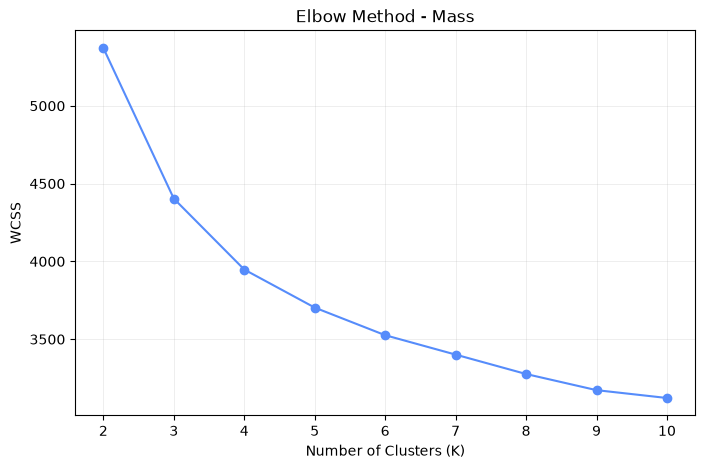

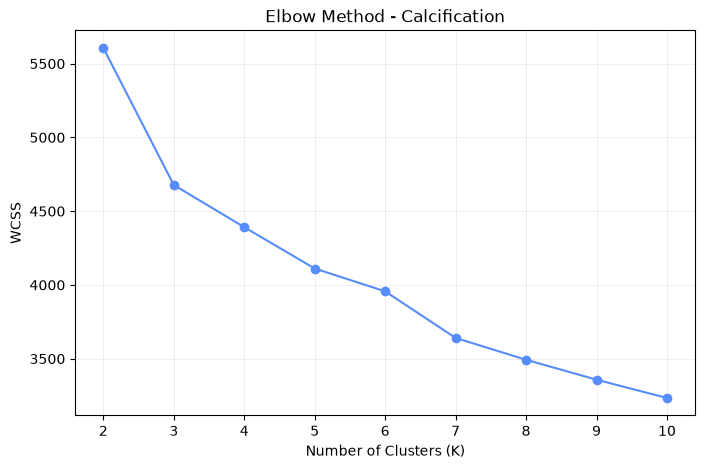

In [28]:
from sklearn.cluster import KMeans

def plot_elbow(X, title):
    k_values = range(2, 11)
    wcss = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        model.fit(X)
        wcss.append(model.inertia_)

    plt.figure(figsize=(8, 5))
    plt.plot(k_values, wcss, marker="o")
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("WCSS")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

plot_elbow(mass_X_train, "Elbow Method - Mass")
plot_elbow(calc_X_train, "Elbow Method - Calcification")

## 4. Applying K-Means Clustering

Apply the K-Means algorithm to group similar cases into four clusters for each dataset.

The clustering is performed independently on the Mass and Calcification datasets.

In [29]:
from sklearn.cluster import KMeans

mass_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

calc_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

mass_clusters = mass_kmeans.fit_predict(mass_X_train)
calc_clusters = calc_kmeans.fit_predict(calc_X_train)

print("Mass cluster distribution:")
print(pd.Series(mass_clusters).value_counts().sort_index())

print("\nCalcification cluster distribution:")
print(pd.Series(calc_clusters).value_counts().sort_index())

Mass cluster distribution:
0    288
1    110
2    348
3    308
Name: count, dtype: int64

Calcification cluster distribution:
0    472
1    209
2    324
3    232
Name: count, dtype: int64


## 5. Analyzing Cluster Composition

Analyze the distribution of pathology classes within each cluster.

Although pathology was not used during clustering, it can be used afterward to evaluate and interpret the resulting groups.

In [30]:
mass_cluster_analysis = pd.crosstab(
    mass_clusters,
    mass_y_train,
    normalize="index"
) * 100

calc_cluster_analysis = pd.crosstab(
    calc_clusters,
    calc_y_train,
    normalize="index"
) * 100

mass_cluster_analysis.columns = ["BENIGN", "BENIGN_WITHOUT_CALLBACK", "MALIGNANT"]
calc_cluster_analysis.columns = ["BENIGN", "BENIGN_WITHOUT_CALLBACK", "MALIGNANT"]

print("Mass Cluster Composition (%):")
print (mass_cluster_analysis.round(2))

print("Calcification Cluster Composition (%):")
print (calc_cluster_analysis.round(2))

Mass Cluster Composition (%):
       BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
row_0                                            
0        5.56                     2.78      91.67
1       83.64                     0.00      16.36
2       62.36                    19.83      17.82
3       44.16                     1.95      53.90
Calcification Cluster Composition (%):
       BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
row_0                                            
0       56.14                     0.00      43.86
1       10.53                    76.08      13.40
2       37.96                     1.54      60.49
3        5.60                    92.67       1.72


## 6. Cluster Composition Visualization

Visualize the pathology distribution within each cluster using stacked bar charts.

This visualization helps compare the composition of the discovered groups.

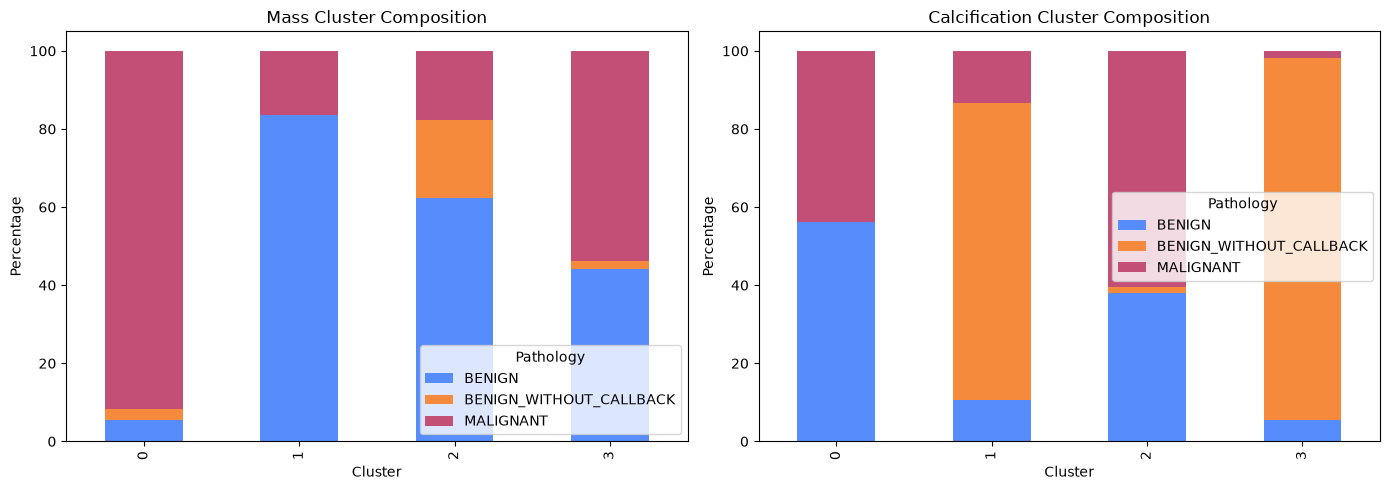

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mass_cluster_analysis.plot(
    kind="bar", stacked=True, ax=axes[0]
)
axes[0].set_title("Mass Cluster Composition")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Percentage")
axes[0].legend(title="Pathology")

calc_cluster_analysis.plot(
    kind="bar", stacked=True, ax=axes[1]
)
axes[1].set_title("Calcification Cluster Composition")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Percentage")
axes[1].legend(title="Pathology")

plt.tight_layout()
plt.show()

## 7. Saving Clustering Results

Save the cluster assignments for both datasets to reuse them in subsequent analysis and semantic graph construction.

In [32]:
np.save("../data/processed/mass_clusters.npy", mass_clusters)
np.save("../data/processed/calc_clusters.npy", calc_clusters)

print("Clustering results saved successfully.")

Clustering results saved successfully.


## 8. Conclusion

K-Means clustering was applied independently to the Mass and Calcification datasets.

Four clusters were identified for each dataset. Their pathology distributions revealed different patterns and group compositions.

These results provide an additional perspective on the clinical data and can support the construction of the semantic graph in the next stage.